In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from google.colab import files

In [4]:
archivo_subido = files.upload()

nombre_archivo = next(iter(archivo_subido))

datos = pd.read_csv(nombre_archivo, skiprows=9)

print("Tamaño del dataset:", datos.shape)
print("\nColumnas:")
print(datos.columns.tolist())

datos.head()

Saving contaminantes_2026.csv to contaminantes_2026.csv
Tamaño del dataset: (1556928, 5)

Columnas:
['date', 'id_station', 'id_parameter', 'valor', 'unit']


,date,id_station,id_parameter,valor,unit
0,2026-01-01 00:00:00,ACO,CO,NaN,15
1,2026-01-01 00:00:00,ACO,NO,NaN,1
2,2026-01-01 00:00:00,ACO,NO2,NaN,1
3,2026-01-01 00:00:00,ACO,NOX,NaN,1
4,2026-01-01 00:00:00,ACO,O3,NaN,1


In [5]:
# Buscar estaciones que tengan los cinco contaminanates necesarios
variables_necesarias = {'O3', 'NO', 'NO2', 'NOX', 'CO'}

parametros_por_estacion = (
    datos.groupby('id_station')['id_parameter']
         .apply(lambda x: set(x.dropna().astype(str)))
)

estaciones_validas = [
    estacion
    for estacion, parametros in parametros_por_estacion.items()
    if variables_necesarias.issubset(parametros)
]

print("Estaciones disponibles:")
print(estaciones_validas)

Estaciones disponibles:
['ACO', 'AJM', 'AJU', 'ATI', 'BJU', 'CAM', 'CCA', 'CHO', 'CUA', 'CUT', 'FAC', 'FAR', 'GAM', 'HGM', 'INN', 'IZT', 'LLA', 'LPR', 'MER', 'MGH', 'MON', 'MPA', 'NEZ', 'PED', 'SAC', 'SAG', 'SFE', 'TAH', 'TLA', 'TLI', 'UAX', 'UIZ', 'VIF', 'XAL']


In [16]:
#Elegir la estación más óptima

if len(estaciones_validas) == 0:
    raise ValueError("No se encontró otra estación con todos los contaminantes requeridos.")

ESTACION = "ATI"

print("Estación seleccionada:", ESTACION)

Estación seleccionada: ATI


In [17]:
#Filtrar la estación
estacion = datos[
    datos['id_station'] == ESTACION
].copy()

print("Registros de la estación:", len(estacion))

estacion.head()

Registros de la estación: 45792


,date,id_station,id_parameter,valor,unit
27,2026-01-01 00:00:00,ATI,CO,0.7,15
28,2026-01-01 00:00:00,ATI,NO,2.0,1
29,2026-01-01 00:00:00,ATI,NO2,21.0,1
30,2026-01-01 00:00:00,ATI,NOX,23.0,1
31,2026-01-01 00:00:00,ATI,O3,18.0,1


In [18]:
# Convertir fecha
estacion['fecha_hora'] = pd.to_datetime(
    estacion['date'],
    errors='coerce'
)

# Revisar si el archivo ya contiene una columna explícita de hora
if 'hour' in estacion.columns:

    estacion['hora'] = pd.to_numeric(
        estacion['hour'],
        errors='coerce'
    )

    # Crear fecha + hora para utilizarla como eje temporal
    fecha_base = estacion['fecha_hora'].dt.normalize()

    estacion['timestamp'] = (
        fecha_base +
        pd.to_timedelta(estacion['hora'], unit='h')
    )

else:

    # Si la hora viene incluida dentro de date
    estacion['hora'] = estacion['fecha_hora'].dt.hour
    estacion['timestamp'] = estacion['fecha_hora']


print("Horas detectadas:")
print(sorted(estacion['hora'].dropna().unique()))

Horas detectadas:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]


In [21]:
#Pasar los contaminantes a columnas
tabla = estacion.pivot_table(
    index=['timestamp', 'hora'],
    columns='id_parameter',
    values='valor',
    aggfunc='mean'
).reset_index()

tabla.head()

id_parameter,timestamp,hora,CO,NO,NO2,NOX,O3,PM10,SO2
0,2026-01-01 00:00:00,0,0.70,2.0,21.0,23.0,18.0,90.0,22.0
1,2026-01-01 01:00:00,1,0.78,3.0,25.0,28.0,11.0,98.0,16.0
2,2026-01-01 02:00:00,2,0.64,2.0,20.0,22.0,13.0,116.0,9.0
3,2026-01-01 03:00:00,3,0.62,5.0,21.0,26.0,8.0,71.0,6.0
4,2026-01-01 04:00:00,4,0.66,8.0,25.0,32.0,4.0,48.0,4.0


In [24]:
contaminantes = ['O3', 'NO', 'NO2', 'NOX', 'CO']

# Convertir a numérico
for variable in contaminantes:
    tabla[variable] = pd.to_numeric(
        tabla[variable],
        errors='coerce'
    )

# Eliminar filas donde falte cualquiera de las variables necesarias
modelo_df = tabla.dropna(
    subset=contaminantes
).copy()

# Orden cronológico
modelo_df = modelo_df.sort_values('timestamp').reset_index(drop=True)

print("Datos disponibles para la regresión:", len(modelo_df))

modelo_df.head()

Datos disponibles para la regresión: 4059


id_parameter,timestamp,hora,CO,NO,NO2,NOX,O3,PM10,SO2
0,2026-01-01 00:00:00,0,0.70,2.0,21.0,23.0,18.0,90.0,22.0
1,2026-01-01 01:00:00,1,0.78,3.0,25.0,28.0,11.0,98.0,16.0
2,2026-01-01 02:00:00,2,0.64,2.0,20.0,22.0,13.0,116.0,9.0
3,2026-01-01 03:00:00,3,0.62,5.0,21.0,26.0,8.0,71.0,6.0
4,2026-01-01 04:00:00,4,0.66,8.0,25.0,32.0,4.0,48.0,4.0


In [25]:
modelo = smf.ols(
    formula='O3 ~ NO + NO2 + NOX + CO',
    data=modelo_df
).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                     O3   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     241.0
Date:                Sat, 03 Oct 2026   Prob (F-statistic):          5.94e-186
Time:                        18:53:18   Log-Likelihood:                -18783.
No. Observations:                4059   AIC:                         3.758e+04
Df Residuals:                    4054   BIC:                         3.761e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     48.1260      0.881     54.615      0.0

In [26]:
print(f"R² del modelo: {modelo.rsquared:.4f}")

resultados = pd.DataFrame({
    'Coeficiente': modelo.params,
    'p-value': modelo.pvalues
})

print("\nCoeficientes y p-values:")
display(resultados)

R² del modelo: 0.1921

Coeficientes y p-values:


,Coeficiente,p-value
Intercept,48.125985,0.000000
NO,0.902029,0.229335
NO2,0.760928,0.311403
NOX,-1.381682,0.065230
CO,6.203340,0.006270


In [27]:
#VIF
predictores = modelo_df[
    ['NO', 'NO2', 'NOX', 'CO']
]

X_vif = sm.add_constant(predictores)

vif = pd.DataFrame()

vif['Variable'] = X_vif.columns[1:]

vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(1, X_vif.shape[1])
]

display(vif)

,Variable,VIF
0,NO,1312.088094
1,NO2,498.717138
2,NOX,2609.470457
3,CO,4.634523


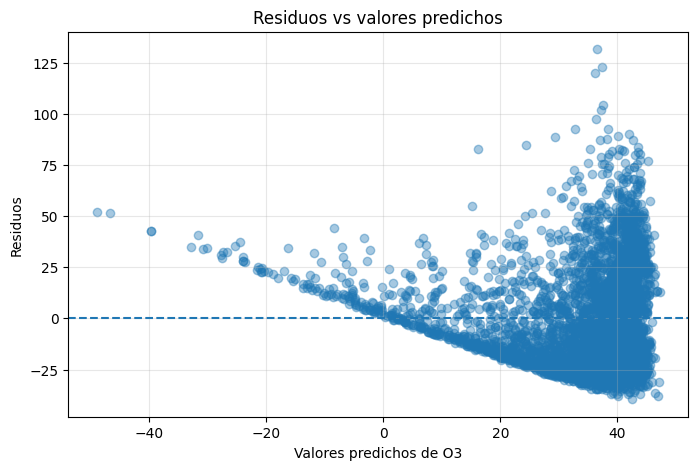

In [28]:
predichos = modelo.fittedvalues
residuos = modelo.resid

plt.figure(figsize=(8, 5))

plt.scatter(
    predichos,
    residuos,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Valores predichos de O3')
plt.ylabel('Residuos')
plt.title('Residuos vs valores predichos')

plt.grid(alpha=0.3)

plt.show()

In [29]:
bp = het_breuschpagan(
    residuos,
    modelo.model.exog
)

resultado_bp = pd.Series(
    bp,
    index=[
        'LM statistic',
        'LM p-value',
        'F statistic',
        'F p-value'
    ]
)

print("Prueba Breusch-Pagan:")
print(resultado_bp)

Prueba Breusch-Pagan:
LM statistic    1.021271e+02
LM p-value      3.466781e-21
F statistic     2.615848e+01
F p-value       1.920039e-21
dtype: float64


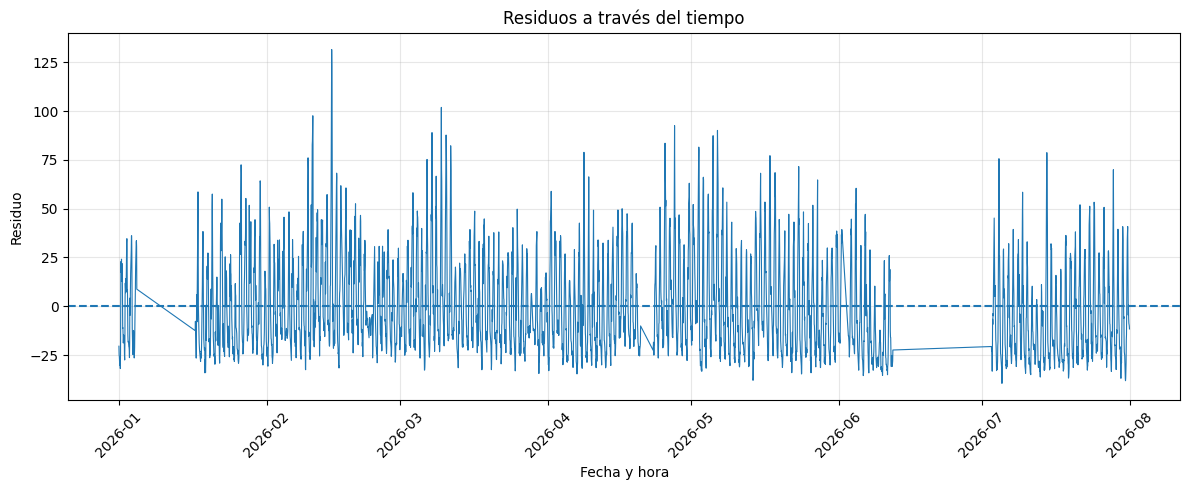

In [30]:
modelo_df['residuo'] = residuos.values

plt.figure(figsize=(12, 5))

plt.plot(
    modelo_df['timestamp'],
    modelo_df['residuo'],
    linewidth=0.8
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Fecha y hora')
plt.ylabel('Residuo')
plt.title('Residuos a través del tiempo')

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
promedio_hora = (
    modelo_df
    .groupby('hora')['residuo']
    .mean()
)

display(promedio_hora)

,residuo
hora,
0,-18.873382
1,-20.366346
2,-22.136540
3,-23.319662
4,-24.753713
5,-22.332419
6,-15.182503
7,-8.822450
8,-4.672741


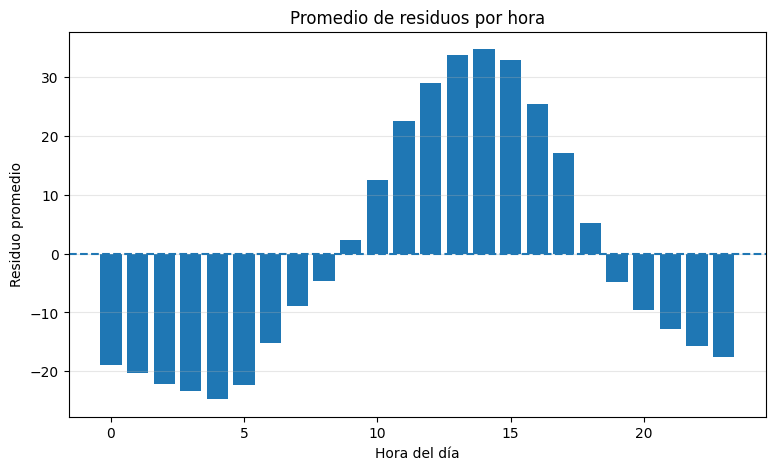

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(
    promedio_hora.index,
    promedio_hora.values
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Hora del día')
plt.ylabel('Residuo promedio')
plt.title('Promedio de residuos por hora')

plt.grid(
    axis='y',
    alpha=0.3
)

plt.show()

In [33]:
dw = durbin_watson(residuos)

print(f"Durbin-Watson: {dw:.4f}")

Durbin-Watson: 0.1667


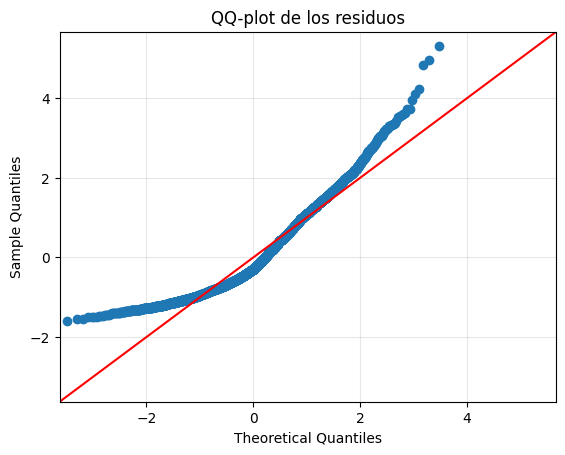

In [34]:
sm.qqplot(
    residuos,
    line='45',
    fit=True
)

plt.title('QQ-plot de los residuos')

plt.grid(alpha=0.3)

plt.show()

El modelo presenta varias violaciones importantes de los supuestos de la regresión lineal. Los valores VIF de NO, NO2 y NOX son extremadamente altos, lo que indica una fuerte multicolinealidad y dificulta estimar de manera estable el efecto individual de cada variable. Además, la prueba de Breusch-Pagan obtuvo un p-value prácticamente igual a cero, mostrando evidencia de heterocedasticidad. El estadístico Durbin-Watson fue de 0.1667, muy alejado de 2, lo que indica una fuerte autocorrelación positiva de los residuos y una violación del supuesto de independencia. El QQ-plot también muestra desviaciones importantes respecto a la línea teórica, especialmente en las colas, por lo que la normalidad de los residuos tampoco se cumple adecuadamente. Por estas razones, el coeficiente de NO2 y su p-value deben interpretarse con mucha cautela. Aunque su p-value es 0.3114 y no muestra significancia estadística al nivel de 0.05, la fuerte multicolinealidad y las violaciones en la estructura de los errores reducen la confiabilidad de la inferencia convencional asociada a ese coeficiente.